# Mini-Projet Séries Temporelles — Partie 4
## Modélisation avancée (LSTM / GRU / hybride) — AAPL & QQQ

Ce notebook **prolonge le travail de l'équipe** (sections 1 → 3.3 : exploration, ADF/KPSS, ARIMA, VAR, Granger, Johansen, GARCH) et couvre :

| Section | Contenu | Barème |
|---|---|---|
| **4.1** | LSTM et GRU, fenêtres glissantes, normalisation sans fuite, courbes de perte, **validation walk-forward** | Bloc B |
| **4.2** | Approche **hybride** GARCH → réseau de neurones (étude d'ablation) | Bloc D |
| **4.4** | Comparaison rigoureuse classique vs avancé (RMSE, MAE, MAPE, **test de Diebold-Mariano**) | Bloc B |

**Comment l'exécuter** : *Kernel → Restart & Run All*. Aucune intervention manuelle n'est nécessaire.
Pour un test rapide (≈ 1 min) mettre `QUICK_RUN = True` dans la cellule de configuration.
**Si ces cellules sont collées à la suite du notebook de l'équipe**, ne pas exécuter la cellule « Étape 0b — rechargement des données » (les variables `dataset`, `train`, `test` existent déjà).

# Partie 4

## Étape 0 — Configuration, reproductibilité et reprise des données de l'équipe

In [ ]:
# === Configuration & imports ==========================================================
# Pourquoi en premier : tout ce qui conditionne la reproductibilité (graine, versions, chemins, hyper-paramètres)
# est centralisé ici pour qu'un correcteur puisse relancer l'étude à l'identique.
import os, re, json, time, warnings, platform
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"      # moins de messages TensorFlow
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"      # calculs plus reproductibles d'une machine à l'autre
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
from scipy import stats

import statsmodels, scipy, sklearn
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from scipy.stats import jarque_bera
from sklearn.model_selection import TimeSeriesSplit
from arch import arch_model
import arch as arch_pkg

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ---- Paramètres généraux (modifiables) -----------------------------------------------
QUICK_RUN = False                      # True = test rapide (3 époques, 2 plis, 1 graine) : ne sert qu'à vérifier que tout tourne
SEED      = 42                         # graine unique → résultats reproductibles
CSV_PATH  = "../data/data_aapl_qqq.csv"   # même fichier que l'équipe (yf.download(...).to_csv)
OUT_DIR   = "../outputs"               # tableaux de résultats (réutilisables pour la partie 6)
LLM_DIR   = "../llm"                   # prompts et réponses des LLM (partie 5)
for d in (OUT_DIR, LLM_DIR): os.makedirs(d, exist_ok=True)

# ---- Hyper-paramètres des réseaux (justifiés dans la section 4.1) ---------------------
CFG = dict(
    windows=[10, 20],      # 10 j couvre les lags significatifs 7-9 vus dans l'ACF/VAR ; 20 j ≈ 1 mois de bourse (= fenêtre de la volatilité)
    units=[16, 32],        # petits réseaux : ~1 700 observations seulement → risque de surapprentissage
    dropout=0.2, lr=1e-3, batch=32,
    max_epochs=80, patience=8, val_frac=0.15,
    cv_splits=4, cv_test_size=200,     # 4 plis walk-forward de 200 jours (≈ 10 mois) chacun
    n_seeds=3)                          # moyenne de 3 initialisations → réduit la variance d'entraînement
if QUICK_RUN:
    CFG.update(windows=[10], units=[16], max_epochs=3, patience=2, cv_splits=2, cv_test_size=120, n_seeds=1)

tf.get_logger().setLevel("ERROR")
np.random.seed(SEED); keras.utils.set_random_seed(SEED)
try: tf.config.experimental.enable_op_determinism()
except Exception: pass
sns.set_theme(style="whitegrid"); plt.rcParams["figure.figsize"] = (12, 4.5)

print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| statsmodels", statsmodels.__version__, "| arch", arch_pkg.__version__,
      "| scikit-learn", sklearn.__version__, "| tensorflow", tf.__version__, "| keras", keras.__version__)
print("QUICK_RUN =", QUICK_RUN, "|", CFG)

Python 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | statsmodels 0.15.0 | arch 8.0.0 | scikit-learn 1.6.1 | tensorflow 2.21.0 | keras 3.13.2
QUICK_RUN = False | {'windows': [10, 20], 'units': [16, 32], 'dropout': 0.2, 'lr': 0.001, 'batch': 32, 'max_epochs': 80, 'patience': 8, 'val_frac': 0.15, 'cv_splits': 4, 'cv_test_size': 200, 'n_seeds': 3}


In [85]:
# === Étape 0b — rechargement des données de l'équipe ==================================
# Pourquoi : rendre ce notebook exécutable seul, en reconstruisant EXACTEMENT les objets de l'équipe
# (mêmes formules : rendement log, MA20, volatilité 20 j, split chronologique 90/10).
def load_prices(csv_path=CSV_PATH):
    """Lit le CSV écrit par yf.download(...).to_csv (3 lignes d'en-tête : Price / Ticker / Date)."""
    if os.path.exists(csv_path):
        raw = pd.read_csv(csv_path, header=[0, 1], index_col=0)
        raw.index = pd.to_datetime(raw.index, errors="coerce")
        raw = raw[raw.index.notna()].astype(float)      # supprime la ligne parasite « Date »
        px, src = raw["Adj Close"], f"CSV local : {csv_path}"
    else:                                               # repli : même appel que l'équipe
        import yfinance as yf
        data = yf.download(["AAPL", "QQQ"], start="2019-01-01", end="2026-10-01", auto_adjust=False, progress=False)
        px, src = data["Adj Close"], "yfinance (téléchargement direct)"
    return px[["AAPL", "QQQ"]].sort_index(), src

prices, source = load_prices()
assert prices.index.is_monotonic_increasing and not prices.index.duplicated().any() and not prices.isna().any().any()
returns = np.log(prices / prices.shift(1)).dropna()                      # r_t = ln(P_t / P_{t-1})
dataset = pd.DataFrame({
    "AAPL": prices["AAPL"], "QQQ": prices["QQQ"],
    "AAPL_Return": returns["AAPL"], "QQQ_Return": returns["QQQ"],
    "AAPL_MA20": prices["AAPL"].rolling(20).mean(),
    "AAPL_Volatility20": returns["AAPL"].rolling(20).std()})
split_index = int(len(dataset) * 0.90)                                   # split CHRONOLOGIQUE (jamais aléatoire)
train, test = dataset.iloc[:split_index].copy(), dataset.iloc[split_index:].copy()

print("Source :", source)
print(f"Période : {dataset.index[0].date()} → {dataset.index[-1].date()} | n = {len(dataset)} | train = {len(train)} | test = {len(test)}")
print(f"Train jusqu'au {train.index[-1].date()} | test à partir du {test.index[0].date()}")
print("✔ identique au notebook de l'équipe (1947 / 1752 / 195)" if (len(dataset), len(train), len(test)) == (1947, 1752, 195)
      else "⚠ dimensions différentes de celles du notebook de l'équipe (1947 / 1752 / 195) : vérifier le fichier CSV")

Source : CSV local : /content/data_aapl_qqq.csv
Période : 2019-01-02 → 2026-09-30 | n = 1947 | train = 1752 | test = 195
Train jusqu'au 2025-12-18 | test à partir du 2025-12-19
✔ identique au notebook de l'équipe (1947 / 1752 / 195)


### Étape 0c — Rappel des résultats de l'équipe (recalculés ici)

**Pourquoi recalculer ?** (1) Ce notebook reste autonome. (2) Les résultats des sections 1-3.3 **justifient les choix de la partie 4**
(quelles entrées donner au réseau ? faut-il modéliser les rendements ou les prix ? faut-il une entrée de volatilité ?)
et **alimentent les prompts de la partie 5** avec des chiffres réels (et non retapés à la main → pas d'erreur de recopie).
Aucun nouveau choix de modèle n'est fait ici : ARIMA(0,1,0) et GARCH(1,1) sont ceux retenus par l'équipe.

In [86]:
def recap_classique(train, dataset):
    """Recalcule les résultats clés des sections 2 à 3.3 (échantillon d'APPRENTISSAGE uniquement)."""
    R = {}
    # -- Stationnarité (ADF H0 = racine unitaire ; KPSS H0 = stationnarité : hypothèses opposées → tests complémentaires)
    rows = []
    for col, nm in [("AAPL", "AAPL prix"), ("QQQ", "QQQ prix"), ("AAPL_Return", "AAPL rendement"), ("QQQ_Return", "QQQ rendement")]:
        s = train[col].dropna(); a = adfuller(s); k = kpss(s, regression="c", nlags="auto")
        rows.append(dict(serie=nm, adf_stat=a[0], adf_p=a[1], kpss_stat=k[0], kpss_p=k[1]))
    R["stationnarite"] = pd.DataFrame(rows).set_index("serie")
    # -- ARIMA(0,1,0) retenu par auto_arima (équipe) + diagnostic des résidus
    arima_res = ARIMA(train["AAPL"].values, order=(0, 1, 0)).fit()
    e = pd.Series(arima_res.resid[1:])
    lb = acorr_ljungbox(e, lags=[10, 20], return_df=True); jb = jarque_bera(e); ar = het_arch(e)
    R["arima"] = dict(aic=arima_res.aic, lb10_p=lb.loc[10, "lb_pvalue"], lb20_p=lb.loc[20, "lb_pvalue"],
                      jb_stat=jb[0], jb_p=jb[1], archlm_stat=ar[0], archlm_p=ar[1])
    # -- VAR sur les rendements + causalité de Granger
    var_model = VAR(train[["AAPL_Return", "QQQ_Return"]].dropna())
    sel = var_model.select_order(maxlags=20); p_aic = sel.selected_orders["aic"]; p_bic = sel.selected_orders["bic"]
    var_res = var_model.fit(p_aic)
    g_q2a = var_res.test_causality("AAPL_Return", ["QQQ_Return"], kind="f")   # H0 : QQQ ne cause pas AAPL
    g_a2q = var_res.test_causality("QQQ_Return", ["AAPL_Return"], kind="f")   # H0 : AAPL ne cause pas QQQ
    R["var"] = dict(lag_aic=int(p_aic), lag_bic=int(p_bic), stable=bool(var_res.is_stable()),
                    corr_resid=float(var_res.resid.corr().iloc[0, 1]),
                    granger_qqq_to_aapl=(g_q2a.test_statistic, g_q2a.pvalue),
                    granger_aapl_to_qqq=(g_a2q.test_statistic, g_a2q.pvalue))
    # -- Cointégration de Johansen sur les log-prix
    jo = coint_johansen(np.log(train[["AAPL", "QQQ"]].dropna()), det_order=0, k_ar_diff=1)
    R["johansen"] = dict(trace=jo.lr1.tolist(), crit5=jo.cvt[:, 1].tolist(), coint=bool(jo.lr1[0] > jo.cvt[0, 1]))
    # -- GARCH(1,1) sur les rendements AAPL (en %) + diagnostic des résidus standardisés
    r_pct = train["AAPL_Return"].dropna() * 100
    g = arch_model(r_pct, mean="Constant", vol="GARCH", p=1, q=1).fit(disp="off")
    z = g.std_resid.dropna(); lbg = acorr_ljungbox(z, lags=[10, 20], return_df=True); arg = het_arch(z); jbg = jarque_bera(z)
    P = g.params
    R["garch"] = dict(mu=P["mu"], omega=P["omega"], alpha=P["alpha[1]"], beta=P["beta[1]"],
                      persistence=P["alpha[1]"] + P["beta[1]"],
                      lb10_p=lbg.loc[10, "lb_pvalue"], lb20_p=lbg.loc[20, "lb_pvalue"],
                      archlm_p=arg[1], jb_stat=jbg[0], jb_p=jbg[1])
    return R, g

R, garch_res = recap_classique(train, dataset)
display(R["stationnarite"].round(4))
print("ARIMA(0,1,0)  :", {k: round(float(v), 4) for k, v in R["arima"].items()})
print("VAR           :", R["var"])
print("Johansen      :", R["johansen"])
print("GARCH(1,1)    :", {k: round(float(v), 4) for k, v in R["garch"].items()})

,adf_stat,adf_p,kpss_stat,kpss_p
serie,,,,
AAPL prix,-0.7299,0.8388,5.9976,0.01
QQQ prix,0.0065,0.9591,5.4912,0.01
AAPL rendement,-13.5753,0.0000,0.2135,0.10
QQQ rendement,-13.2064,0.0000,0.0903,0.10


ARIMA(0,1,0)  : {'aic': 8557.0746, 'lb10_p': 0.0656, 'lb20_p': 0.0704, 'jb_stat': 5140.8186, 'jb_p': 0.0, 'archlm_stat': 257.9666, 'archlm_p': 0.0}
VAR           : {'lag_aic': 9, 'lag_bic': 1, 'stable': True, 'corr_resid': 0.8154884979568195, 'granger_qqq_to_aapl': (np.float64(3.109370131211389), np.float64(0.0009914162824246797)), 'granger_aapl_to_qqq': (np.float64(1.0962004836727854), np.float64(0.3617962842416341))}
Johansen      : {'trace': [10.855268029330174, 0.485214292580505], 'crit5': [15.4943, 3.8415], 'coint': False}
GARCH(1,1)    : {'mu': 0.1753, 'omega': 0.1577, 'alpha': 0.1044, 'beta': 0.8505, 'persistence': 0.9549, 'lb10_p': 0.724, 'lb20_p': 0.7107, 'archlm_p': 0.5653, 'jb_stat': 466.2971, 'jb_p': 0.0}


## 4.0 — Formulation du problème pour les réseaux de neurones

**Cible** : prédire le **rendement logarithmique d'AAPL du lendemain**, $r_{t+1}$, à partir des $W$ derniers jours d'observations.
Le prix prévu s'en déduit : $\hat P_{t+1} = P_t \cdot e^{\hat r_{t+1}}$.

**Pourquoi modéliser les rendements et non les prix ?**
1. **Stationnarité** — d'après ADF/KPSS de l'équipe, les prix sont non stationnaires (ADF p ≈ 0.84 / 0.96 ; KPSS rejette) alors que les rendements sont stationnaires. Un réseau apprend mal sur une série dont la moyenne dérive.
2. **Extrapolation** — un LSTM/GRU utilise des activations bornées (tanh/sigmoïde) ; si le test contient des prix **jamais vus** à l'entraînement (cas ici : l'action monte, voir cellule suivante), la normalisation min-max sort de l'intervalle [0, 1] et le réseau « plafonne ». Les rendements restent dans la même plage en train et en test.
3. **Comparabilité** — l'ARIMA(0,1,0) de l'équipe est une marche aléatoire : sa prévision est $\hat P_{t+1}=P_t$, soit $\hat r_{t+1}=0$. Même cible → comparaison équitable.

**Variables d'entrée (justifiées par les sections 3.2 et 3.3 de l'équipe)**

| Variable | Pourquoi |
|---|---|
| `AAPL_Return` | historique propre de la cible (le VAR d'ordre 9 suggère des lags jusqu'à 9) |
| `QQQ_Return` | **Granger : QQQ → AAPL significatif** (F = 3.11, p = 0.001), alors que AAPL → QQQ ne l'est pas |
| `AAPL_Volatility20` | **effets ARCH très forts** (ARCH-LM p ≈ 1e-49) : le régime de volatilité est une information utile |

**Règles anti-fuite d'information (data leakage)** : split chronologique ; normalisation avec moyenne/écart-type **du train uniquement** (et recalculés dans chaque pli de la validation croisée) ; une fenêtre ne contient que des jours ≤ $t$.

In [87]:
# Illustration du point (2) : plage des prix en train vs test
print(f"AAPL prix — max train : {train['AAPL'].max():.1f} | max test : {test['AAPL'].max():.1f}")
print(f"Rendements — écart-type train : {train['AAPL_Return'].std():.4f} | test : {test['AAPL_Return'].std():.4f}")
if test["AAPL"].max() > train["AAPL"].max():
    print("→ le test contient des prix hors de la plage d'entraînement : modéliser les PRIX avec un réseau serait biaisé ; on modélise les RENDEMENTS.")

AAPL prix — max train : 285.4 | max test : 341.1
Rendements — écart-type train : 0.0196 | test : 0.0166
→ le test contient des prix hors de la plage d'entraînement : modéliser les PRIX avec un réseau serait biaisé ; on modélise les RENDEMENTS.


In [88]:
# === Préparation : variables, fenêtres glissantes, normalisation sans fuite ===========
FEATURES_BASE = ["AAPL_Return", "QQQ_Return", "AAPL_Volatility20"]     # la colonne 0 est TOUJOURS la cible
feat = dataset[FEATURES_BASE].dropna()                                   # retire les lignes initiales sans rendement / volatilité
train_end, test_start = train.index[-1], test.index[0]
cut_final = int((feat.index <= train_end).sum())                         # nb de lignes de la période d'apprentissage
n_test = len(feat) - cut_final
print(f"lignes utilisables : {len(feat)} | apprentissage : {cut_final} | test : {n_test}")
assert n_test == len(test), "le test doit contenir tous les jours du split de l'équipe"

def fit_scaler(F, cut):
    """Moyenne / écart-type calculés sur les lignes [0:cut] SEULEMENT (= information disponible à l'époque)."""
    return F[:cut].mean(axis=0), F[:cut].std(axis=0, ddof=0)

def make_windows(Fs, W):
    """Fenêtres glissantes : X[i] = lignes (o-W+1 … o) ; y[i] = cible standardisée du jour o+1 (colonne 0)."""
    origins = np.arange(W - 1, Fs.shape[0] - 1)
    X = np.stack([Fs[o - W + 1:o + 1] for o in origins])
    y = Fs[origins + 1, 0]
    return X, y, origins

F = feat.values.astype("float64")
mu, sd = fit_scaler(F, cut_final); Fs = (F - mu) / sd
X_demo, y_demo, o_demo = make_windows(Fs, 10)
print("exemple (W=10) : X", X_demo.shape, "= (échantillons, fenêtre, variables) | y", y_demo.shape)
# contrôle anti-fuite : la fenêtre du dernier échantillon de train ne dépasse pas la dernière date de train
last_tr = np.where(o_demo + 1 <= cut_final - 1)[0][-1]
print("dernière date du dernier échantillon de train :", feat.index[o_demo[last_tr]].date(), "→ cible :", feat.index[o_demo[last_tr] + 1].date())

lignes utilisables : 1927 | apprentissage : 1732 | test : 195
exemple (W=10) : X (1917, 10, 3) = (échantillons, fenêtre, variables) | y (1917,)
dernière date du dernier échantillon de train : 2025-12-17 → cible : 2025-12-18


### Références à battre (baselines)

Un réseau n'a de valeur que s'il fait mieux qu'une référence simple. Sur des rendements boursiers quotidiens, la référence est redoutable :

- **ARIMA(0,1,0) = marche aléatoire** (modèle retenu par l'équipe) : $\hat r_{t+1}=0$, soit $\hat P_{t+1}=P_t$. On **vérifie numériquement** ci-dessous que le `ARIMA(0,1,0)` de statsmodels donne bien cette prévision à un pas.
- **Marche aléatoire avec dérive** : $\hat r_{t+1}=\bar r_{train}$ (moyenne des rendements d'apprentissage).

In [89]:
# --- Données alignées pour l'évaluation sur le TEST (prévision à 1 jour, 195 origines) ---
tgt_dates = feat.index[cut_final:]                # jours à prévoir (t+1)
org_dates = feat.index[cut_final - 1:-1]          # jours d'origine (t) : seule l'information ≤ t est utilisée
P_org  = dataset.loc[org_dates, "AAPL"].values    # P_t
P_next = dataset.loc[tgt_dates, "AAPL"].values    # P_{t+1} observé
r_next = F[cut_final:, 0]                         # r_{t+1} observé
drift  = F[:cut_final, 0].mean()

# Vérification : ARIMA(0,1,0) statsmodels (paramètres figés sur le train, mis à jour avec le test) = prévision naïve P_t
arima_fit = ARIMA(train["AAPL"].values, order=(0, 1, 0)).fit()
arima_pred = arima_fit.append(test["AAPL"].values, refit=False).get_prediction(start=len(train)).predicted_mean
print("max |prévision ARIMA(0,1,0) − P_t| =", float(np.max(np.abs(arima_pred - dataset["AAPL"].shift(1).iloc[split_index:].values))), "(≈ 0 ⇒ ARIMA(0,1,0) = prévision naïve)")

def price_metrics(y, yhat):
    e = y - yhat
    return dict(MSE=np.mean(e**2), RMSE=np.sqrt(np.mean(e**2)), MAE=np.mean(np.abs(e)), MAPE=100*np.mean(np.abs(e/y)))

def return_metrics(r, rhat):
    e = r - rhat
    hit = np.nan if np.allclose(rhat, 0) else float(np.mean(np.sign(rhat) == np.sign(r)))
    return {"RMSE_ret": np.sqrt(np.mean(e**2)), "MAE_ret": np.mean(np.abs(e)), "Hit": hit}

# Dictionnaire central : nom du modèle → rendements prévus (à t+1) sur le test
PRED = {"ARIMA(0,1,0) / naïf": np.zeros(n_test), "Marche aléatoire + dérive": np.full(n_test, drift)}
NEXT = {"ARIMA(0,1,0) / naïf": 0.0, "Marche aléatoire + dérive": float(drift)}   # prévision du jour suivant la fin des données (pour la partie 5)
print("dérive d'apprentissage (rendement moyen/jour) :", round(float(drift), 6))

max |prévision ARIMA(0,1,0) − P_t| = 2.842170943040401e-14 (≈ 0 ⇒ ARIMA(0,1,0) = prévision naïve)
dérive d'apprentissage (rendement moyen/jour) : 0.001118


## 4.1 — Réseaux récurrents : LSTM et GRU

### Choix d'architecture et d'hyper-paramètres (et pourquoi)
- **Une seule couche récurrente + Dropout 0.2 + Dense(1)** : ~1 700 observations seulement et un rapport signal/bruit très faible sur des rendements quotidiens. Un réseau profond ou large mémoriserait le bruit. Le dropout est la régularisation principale ; la couche récurrente est l'élément qui diffère entre **LSTM** (3 portes + cellule mémoire) et **GRU** (2 portes, ~25 % de paramètres en moins, souvent aussi bon sur petits jeux de données).
- **Fenêtre $W$ ∈ {10, 20}** : l'ACF/PACF et le VAR de l'équipe signalent des dépendances jusqu'au lag 9 (VAR-AIC = 9) → $W=10$ les couvre ; $W=20$ ≈ un mois de bourse, comme la fenêtre de la volatilité.
- **Unités ∈ {16, 32}** : petits réseaux (≈ 1–5 k paramètres).
- **Perte de Huber** (δ = 1 sur cible standardisée) : les rendements ont un kurtosis en excès de 6.5 (AAPL) et 7.3 (QQQ) ; la Huber limite l'influence des jours extrêmes (krach de mars 2020 par ex.) alors que la MSE les sur-pondère. L'évaluation finale reste faite en RMSE/MAE.
- **Adam (lr = 1e-3), EarlyStopping** sur la perte de validation (derniers 15 % chronologiques du train, `restore_best_weights`) : arrête l'entraînement dès que le réseau commence à surapprendre.
- **Moyenne de 3 graines** : l'initialisation aléatoire change les résultats d'un réseau ; moyenner 3 réseaux stabilise la prévision.
- Mélanger (`shuffle`) les fenêtres **à l'intérieur du train** n'est pas une fuite : chaque fenêtre est autonome. Ce qui est interdit, c'est un split train/test aléatoire — le nôtre est chronologique.

### Validation croisée temporelle (walk-forward, fenêtre extensible)
Le jeu d'apprentissage est découpé en plis successifs : on entraîne sur le passé, on évalue sur les 200 jours suivants, puis on **étend** le passé et on recommence. Jamais de k-fold classique.
Le **jeu de test final n'est pas utilisé** ici : la validation croisée sert à **choisir** ($W$, unités) ; le test sert à **juger**.
Métriques de pli : `ratio = RMSE(modèle) / RMSE(naïf)` (**< 1 ⇒ bat la marche aléatoire**) et `ratio_derive = RMSE(modèle) / RMSE(marche aléatoire + dérive)`. Ce second ratio est le plus exigeant : un réseau qui se contente de reproduire le rendement moyen (la dérive) bat le naïf sans rien « comprendre » ; il ne doit pas être félicité pour cela.

In [90]:
# === Constructeurs et entraînement ====================================================
def build_model(kind, window, n_feat, units):
    """LSTM ou GRU : 1 couche récurrente → Dropout → Dense(1). Petit modèle volontairement (peu de données)."""
    Rnn = layers.LSTM if kind == "LSTM" else layers.GRU
    m = keras.Sequential([layers.Input(shape=(window, n_feat)), Rnn(units),
                          layers.Dropout(CFG["dropout"]), layers.Dense(1)])
    m.compile(optimizer=keras.optimizers.Adam(CFG["lr"]), loss=keras.losses.Huber(delta=1.0))
    return m

def fit_one(kind, X, y, window, units, seed):
    """Entraîne un réseau ; validation = derniers 15 % (chronologiques) des échantillons d'apprentissage."""
    keras.utils.set_random_seed(seed)
    model = build_model(kind, window, X.shape[2], units)
    n_val = max(int(len(X) * CFG["val_frac"]), 1)
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=CFG["patience"], restore_best_weights=True)
    hist = model.fit(X[:-n_val], y[:-n_val], validation_data=(X[-n_val:], y[-n_val:]),
                     epochs=CFG["max_epochs"], batch_size=CFG["batch"], shuffle=True, callbacks=[es], verbose=0)
    return model, hist.history

def walk_forward_cv(kind, W, units, F, cut, seed=SEED):
    """Validation croisée walk-forward sur la période d'apprentissage. Normalisation recalculée dans chaque pli."""
    tscv = TimeSeriesSplit(n_splits=CFG["cv_splits"], test_size=CFG["cv_test_size"])
    out = []
    for k, (tr_rows, te_rows) in enumerate(tscv.split(np.arange(cut))):
        last = tr_rows[-1]
        m_, s_ = fit_scaler(F, last + 1); Fs_ = (F - m_) / s_
        X, y, orig = make_windows(Fs_, W); tgt = orig + 1
        tr = tgt <= last
        te = (tgt >= te_rows[0]) & (tgt <= te_rows[-1])
        model, _ = fit_one(kind, X[tr], y[tr], W, units, seed + k)
        pred = model.predict(X[te], verbose=0).ravel() * s_[0] + m_[0]
        true = F[tgt[te], 0]
        rmse, rmse0 = np.sqrt(np.mean((true - pred)**2)), np.sqrt(np.mean(true**2))
        rmse_d = np.sqrt(np.mean((true - F[:last + 1, 0].mean())**2))         # référence « marche aléatoire + dérive » (dérive du pli)
        out.append(dict(pli=k + 1, rmse=rmse, rmse_naif=rmse0, ratio=rmse / rmse0, ratio_derive=rmse / rmse_d,
                        hit=np.mean(np.sign(pred) == np.sign(true))))
        keras.backend.clear_session()
    return pd.DataFrame(out)

In [91]:
# === Recherche d'hyper-paramètres par walk-forward (LSTM et GRU) ======================
t0, grid_rows, folds = time.time(), [], {}
for kind in ["LSTM", "GRU"]:
    for W in CFG["windows"]:
        for u in CFG["units"]:
            cv = walk_forward_cv(kind, W, u, F, cut_final)
            folds[(kind, W, u)] = cv
            grid_rows.append(dict(modele=kind, fenetre=W, unites=u, ratio_moy=cv.ratio.mean(), ratio_std=cv.ratio.std(ddof=0),
                                  ratio_derive_moy=cv.ratio_derive.mean(), rmse_moy=cv.rmse.mean(), hit_moy=cv.hit.mean()))
            print(f"{kind:4s} W={W:2d} u={u:2d} | RMSE/naïf = {cv.ratio.mean():.4f} ± {cv.ratio.std(ddof=0):.4f} | RMSE/dérive = {cv.ratio_derive.mean():.4f} | hit = {cv.hit.mean():.3f}")
grid_df = pd.DataFrame(grid_rows)
print(f"durée : {time.time() - t0:.0f} s")
best = grid_df.loc[grid_df.groupby("modele")["ratio_moy"].idxmin()].set_index("modele")
BEST = {k: (int(r.fenetre), int(r.unites)) for k, r in best.iterrows()}
print("\nConfiguration retenue (ratio moyen le plus bas) :", BEST)
display(grid_df.round(4))

LSTM W=10 u=16 | RMSE/naïf = 1.0056 ± 0.0121 | RMSE/dérive = 1.0059 | hit = 0.533
LSTM W=10 u=32 | RMSE/naïf = 1.0024 ± 0.0119 | RMSE/dérive = 1.0027 | hit = 0.545
LSTM W=20 u=16 | RMSE/naïf = 1.0043 ± 0.0100 | RMSE/dérive = 1.0047 | hit = 0.532
LSTM W=20 u=32 | RMSE/naïf = 1.0022 ± 0.0094 | RMSE/dérive = 1.0025 | hit = 0.522
GRU  W=10 u=16 | RMSE/naïf = 1.0124 ± 0.0110 | RMSE/dérive = 1.0128 | hit = 0.529
GRU  W=10 u=32 | RMSE/naïf = 1.0044 ± 0.0146 | RMSE/dérive = 1.0047 | hit = 0.537
GRU  W=20 u=16 | RMSE/naïf = 1.0124 ± 0.0114 | RMSE/dérive = 1.0127 | hit = 0.529
GRU  W=20 u=32 | RMSE/naïf = 1.0056 ± 0.0174 | RMSE/dérive = 1.0059 | hit = 0.541
durée : 321 s

Configuration retenue (ratio moyen le plus bas) : {'GRU': (10, 32), 'LSTM': (20, 32)}


,modele,fenetre,unites,ratio_moy,ratio_std,ratio_derive_moy,rmse_moy,hit_moy
0,LSTM,10,16,1.0056,0.0121,1.0059,0.0168,0.5325
1,LSTM,10,32,1.0024,0.0119,1.0027,0.0168,0.5450
2,LSTM,20,16,1.0043,0.0100,1.0047,0.0168,0.5325
3,LSTM,20,32,1.0022,0.0094,1.0025,0.0168,0.5225
4,GRU,10,16,1.0124,0.0110,1.0128,0.0169,0.5288
5,GRU,10,32,1.0044,0.0146,1.0047,0.0168,0.5375
6,GRU,20,16,1.0124,0.0114,1.0127,0.0169,0.5287
7,GRU,20,32,1.0056,0.0174,1.0059,0.0168,0.5412


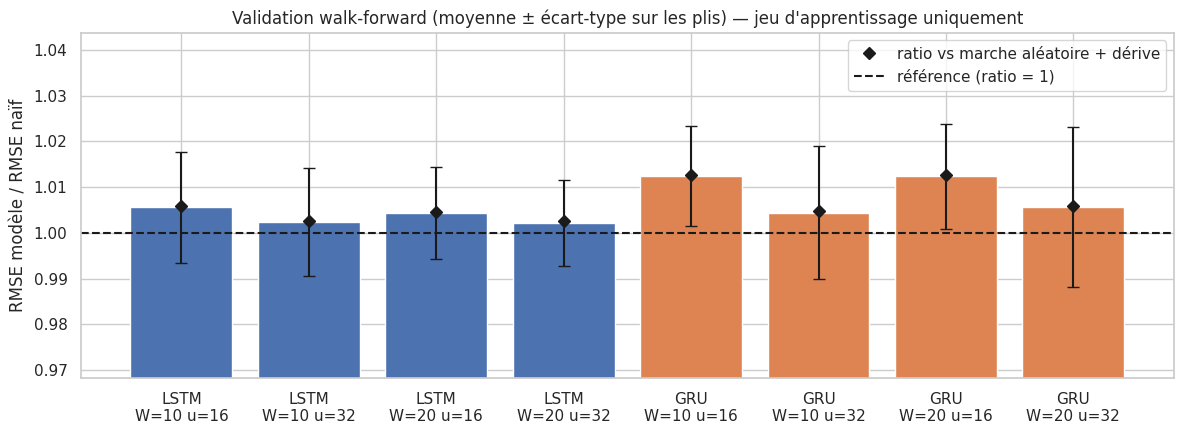

Lecture : barre (vs naïf) < 1 mais losange (vs dérive) ≈ 1 ⇒ le réseau ne fait que reproduire le rendement moyen. L'écart-type indique la stabilité d'un pli à l'autre.


In [92]:
# Visualisation : robustesse de chaque configuration (ratio < 1 ⇒ bat la marche aléatoire)
lab = [f"{r.modele}\nW={r.fenetre} u={r.unites}" for r in grid_df.itertuples()]
plt.figure(figsize=(12, 4.5))
plt.bar(lab, grid_df.ratio_moy, yerr=grid_df.ratio_std, capsize=4, color=["#4C72B0" if m == "LSTM" else "#DD8452" for m in grid_df.modele])
plt.plot(lab, grid_df.ratio_derive_moy, "kD", label="ratio vs marche aléatoire + dérive")
plt.axhline(1.0, color="k", ls="--", label="référence (ratio = 1)")
lo = max(0.0, float(min((grid_df.ratio_moy - grid_df.ratio_std).min(), grid_df.ratio_derive_moy.min())) - 0.02); hi = float((grid_df.ratio_moy + grid_df.ratio_std).max()) + 0.02
plt.ylim(lo, max(hi, 1.02)); plt.ylabel("RMSE modèle / RMSE naïf"); plt.legend()
plt.title("Validation walk-forward (moyenne ± écart-type sur les plis) — jeu d'apprentissage uniquement"); plt.tight_layout(); plt.show()
print("Lecture : barre (vs naïf) < 1 mais losange (vs dérive) ≈ 1 ⇒ le réseau ne fait que reproduire le rendement moyen. L'écart-type indique la stabilité d'un pli à l'autre.")

### Entraînement final, courbes de perte et prévisions sur le test
Chaque architecture retenue est réentraînée sur **tout** le jeu d'apprentissage (normalisation train-only), avec 3 graines ; la prévision est la moyenne des 3 réseaux.
Les **courbes de perte train/validation** documentent la procédure : une validation qui remonte pendant que le train descend = surapprentissage (c'est ce que l'EarlyStopping coupe).

LSTM (W=20, unités=32) entraîné : 9 époques (graine 0)
GRU (W=10, unités=32) entraîné : 21 époques (graine 0)


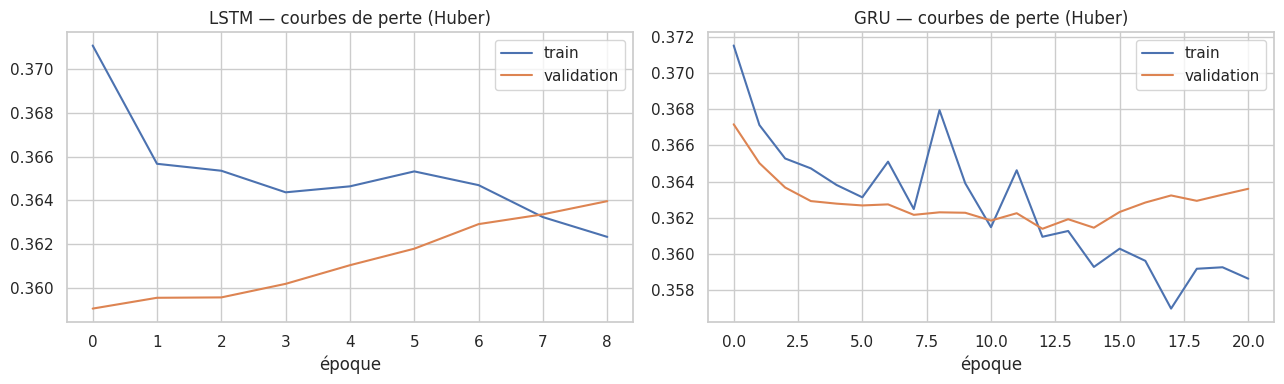

In [93]:
def train_final(kind, W, units, F, cut):
    """Entraîne n_seeds réseaux sur le train complet ; renvoie (rendements prévus sur le test, historique graine 0, prévision J+1 après la dernière date)."""
    m_, s_ = fit_scaler(F, cut); Fs_ = (F - m_) / s_
    X, y, orig = make_windows(Fs_, W); tgt = orig + 1
    tr, te = tgt <= cut - 1, tgt >= cut
    X_last = Fs_[-W:][None, :, :]                       # dernière fenêtre disponible → prévision du jour suivant la fin des données
    preds, nxt, hist0 = [], [], None
    for i in range(CFG["n_seeds"]):
        model, h = fit_one(kind, X[tr], y[tr], W, units, SEED + i)
        preds.append(model.predict(X[te], verbose=0).ravel()); nxt.append(float(model.predict(X_last, verbose=0).ravel()[0]))
        if i == 0: hist0 = h
        keras.backend.clear_session()
    rhat = np.mean(preds, axis=0) * s_[0] + m_[0]
    assert len(rhat) == n_test
    return rhat, hist0, float(np.mean(nxt) * s_[0] + m_[0])

HIST = {}
for kind in ["LSTM", "GRU"]:
    W, u = BEST[kind]
    PRED[kind], HIST[kind], NEXT[kind] = train_final(kind, W, u, F, cut_final)
    print(f"{kind} (W={W}, unités={u}) entraîné : {len(HIST[kind]['loss'])} époques (graine 0)")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, kind in zip(ax, ["LSTM", "GRU"]):
    a.plot(HIST[kind]["loss"], label="train"); a.plot(HIST[kind]["val_loss"], label="validation")
    a.set_title(f"{kind} — courbes de perte (Huber)"); a.set_xlabel("époque"); a.legend()
plt.tight_layout(); plt.show()

## 4.2 — Approche hybride : GARCH → réseau de neurones

**Idée.** Le GARCH(1,1) de l'équipe capte très bien la **volatilité conditionnelle** (résidus standardisés sans autocorrélation ni effet ARCH), mais pas de non-linéarités dans la moyenne. On donne donc au réseau la **volatilité du lendemain prévue par le GARCH**, $\hat\sigma_{t+1}$, en entrée supplémentaire : l'économétrie fournit une information structurée, le réseau apprend ce qu'il peut en faire.

**Pourquoi pas « ARIMA + LSTM sur les résidus » (l'exemple de l'énoncé) ?** L'ARIMA retenu est (0,1,0) : sans terme AR/MA, il ne retire **aucune structure** ; ses résidus sont simplement les variations de prix, donc un LSTM dessus reviendrait à notre LSTM sur les rendements. Le couplage GARCH → réseau est le seul qui apporte une information nouvelle ici.

**Absence de fuite.** $\hat\sigma_{t+1}^2=\omega+\alpha\,\varepsilon_t^2+\beta\,\sigma_t^2$ ne dépend que de données ≤ $t$ ; sur le test, les paramètres sont ceux **estimés sur le train** (`fix`). On le vérifie numériquement. **Étude d'ablation** : mêmes hyper-paramètres que le modèle sans GARCH → toute différence vient de la nouvelle variable.

In [94]:
# --- Volatilité conditionnelle du lendemain : paramètres GARCH figés sur le train, filtrage sur toute la série ---
all_ret_pct = returns["AAPL"] * 100
garch_fixed = arch_model(all_ret_pct, mean="Constant", vol="GARCH", p=1, q=1).fix(garch_res.params)
cv_sig = garch_fixed.conditional_volatility                      # σ_t (connu dès t-1)
sig_next = cv_sig.shift(-1)                                      # σ_{t+1} (connu dès t) = variable utilisable à la date t
sig_next.iloc[-1] = float(np.sqrt(garch_fixed.forecast(horizon=1).variance.iloc[-1, 0]))   # dernier jour : prévision à 1 pas

# Contrôle anti-fuite : σ²_{t+1} = ω + α·ε²_t + β·σ²_t doit retrouver exactement la série décalée
P_ = garch_res.params; eps = all_ret_pct - P_["mu"]
check = P_["omega"] + P_["alpha[1]"] * eps**2 + P_["beta[1]"] * cv_sig**2
print("contrôle fuite — écart max :", float(np.max(np.abs(np.sqrt(check.iloc[:-1]) - cv_sig.shift(-1).iloc[:-1]).dropna())), "(≈ 0 ⇒ σ_{t+1} ne dépend que de données ≤ t)")

dataset["GARCH_Sigma_next"] = sig_next.reindex(dataset.index)
FEATURES_HYB = FEATURES_BASE + ["GARCH_Sigma_next"]
feat_h = dataset[FEATURES_HYB].dropna()
assert (feat_h.index == feat.index).all()
F_h = feat_h.values.astype("float64")

for kind in ["LSTM", "GRU"]:
    W, u = BEST[kind]                                            # mêmes hyper-paramètres → ablation propre
    PRED[f"{kind}+GARCH"], HIST[f"{kind}+GARCH"], NEXT[f"{kind}+GARCH"] = train_final(kind, W, u, F_h, cut_final)
    print(f"{kind}+GARCH entraîné ({len(HIST[f'{kind}+GARCH']['loss'])} époques, graine 0)")

contrôle fuite — écart max : 8.881784197001252e-16 (≈ 0 ⇒ σ_{t+1} ne dépend que de données ≤ t)
LSTM+GARCH entraîné (9 époques, graine 0)
GRU+GARCH entraîné (16 époques, graine 0)


## 4.4 — Comparaison rigoureuse : classique vs réseaux de neurones (test, prévision à 1 jour)

**Métriques** : MSE, RMSE, MAE, MAPE sur les **prix** (comme l'ARIMA de l'équipe) ; RMSE/MAE sur les **rendements** (échelle où le signal se joue) ; `Hit` = % de jours où le signe du rendement est bien prévu (non défini pour le modèle naïf qui prévoit 0). Le MAPE n'est pas calculé sur les rendements (division par des valeurs proches de 0 → non pertinent).

**Test de Diebold-Mariano** (perte quadratique, horizon 1, correction de Harvey-Leybourne-Newbold) : ne pas se contenter de comparer des RMSE bruts, mais tester si l'écart est statistiquement significatif. Convention : **DM < 0 ⇒ le modèle a une perte plus faible que la référence (ARIMA(0,1,0))**.

In [95]:
def diebold_mariano(e_model, e_ref, h=1, power=2):
    """DM (Harvey-Leybourne-Newbold). d_t = |e_model|^p − |e_ref|^p ; DM<0 ⇒ le modèle est meilleur que la référence."""
    d = np.abs(np.asarray(e_model))**power - np.abs(np.asarray(e_ref))**power
    T, dbar = len(d), d.mean()
    gam = lambda k: np.sum((d[k:] - dbar) * (d[:T - k] - dbar)) / T
    var = gam(0) + 2 * sum(gam(k) for k in range(1, h))
    if var <= 1e-18: return np.nan, np.nan
    dm = dbar / np.sqrt(var / T) * np.sqrt((T + 1 - 2*h + h*(h - 1) / T) / T)
    return float(dm), float(2 * (1 - stats.t.cdf(abs(dm), df=T - 1)))

REF = "ARIMA(0,1,0) / naïf"
rows = []
for name, rhat in PRED.items():
    Phat = P_org * np.exp(rhat)
    row = dict(modele=name, **price_metrics(P_next, Phat), **return_metrics(r_next, rhat))
    e_p, e_r = P_next - Phat, r_next - rhat
    ref_p, ref_r = P_next - P_org, r_next
    row["DM_prix"], row["p_DM_prix"] = diebold_mariano(e_p, ref_p) if name != REF else (np.nan, np.nan)
    row["DM_rend"], row["p_DM_rend"] = diebold_mariano(e_r, ref_r) if name != REF else (np.nan, np.nan)
    rows.append(row)
results_df = pd.DataFrame(rows).set_index("modele")
display(results_df.round(4))

def verdict(dm, p):
    if np.isnan(p): return "référence"
    if p < 0.05: return "significativement MEILLEUR" if dm < 0 else "significativement MOINS BON"
    return "différence non significative"
results_df["verdict_vs_ARIMA"] = [verdict(r.DM_rend, r.p_DM_rend) for r in results_df.itertuples()]
print("\nVerdict Diebold-Mariano (rendements, α = 5 %) :"); display(results_df[["RMSE_ret", "p_DM_rend", "verdict_vs_ARIMA"]].round(4))

# Référence plus exigeante : « marche aléatoire + dérive » (un réseau qui prévoit juste le rendement moyen bat le naïf sans rien apprendre)
print("\nDiebold-Mariano contre « marche aléatoire + dérive » (rendements) :")
for nm in ["LSTM", "GRU", "LSTM+GARCH", "GRU+GARCH"]:
    dm, p = diebold_mariano(r_next - PRED[nm], r_next - PRED["Marche aléatoire + dérive"])
    results_df.loc[nm, "p_DM_vs_derive"] = p
    print(f"  {nm:11s}: DM = {dm:+.3f}, p = {p:.3f} → {verdict(dm, p)}")

# Ablation : le GARCH apporte-t-il quelque chose au réseau ?
for kind in ["LSTM", "GRU"]:
    dm, p = diebold_mariano(r_next - PRED[f"{kind}+GARCH"], r_next - PRED[kind])
    print(f"Ablation {kind}+GARCH vs {kind} : DM = {dm:.3f}, p = {p:.3f} → {verdict(dm, p)}")

,MSE,RMSE,MAE,MAPE,RMSE_ret,MAE_ret,Hit,DM_prix,p_DM_prix,DM_rend,p_DM_rend
modele,,,,,,,,,,,
"ARIMA(0,1,0) / naïf",23.4163,4.8390,3.4608,1.1963,0.0166,0.0120,NaN,NaN,NaN,NaN,NaN
Marche aléatoire + dérive,23.3339,4.8305,3.4456,1.1921,0.0166,0.0119,0.5282,-0.3559,0.7223,-0.4119,0.6809
LSTM,23.5963,4.8576,3.4581,1.1967,0.0166,0.0119,0.5231,0.5083,0.6118,0.4784,0.6329
GRU,22.9732,4.7930,3.4050,1.1787,0.0164,0.0118,0.5692,-1.3282,0.1857,-1.1850,0.2375
LSTM+GARCH,23.5757,4.8555,3.4595,1.1972,0.0166,0.0120,0.5282,0.4613,0.6451,0.4105,0.6819
GRU+GARCH,23.0278,4.7987,3.4036,1.1780,0.0164,0.0118,0.5538,-1.1560,0.2491,-1.1047,0.2707



Verdict Diebold-Mariano (rendements, α = 5 %) :


,RMSE_ret,p_DM_rend,verdict_vs_ARIMA
modele,,,
"ARIMA(0,1,0) / naïf",0.0166,NaN,référence
Marche aléatoire + dérive,0.0166,0.6809,différence non significative
LSTM,0.0166,0.6329,différence non significative
GRU,0.0164,0.2375,différence non significative
LSTM+GARCH,0.0166,0.6819,différence non significative
GRU+GARCH,0.0164,0.2707,différence non significative



Diebold-Mariano contre « marche aléatoire + dérive » (rendements) :
  LSTM       : DM = +1.643, p = 0.102 → différence non significative
  GRU        : DM = -1.319, p = 0.189 → différence non significative
  LSTM+GARCH : DM = +1.427, p = 0.155 → différence non significative
  GRU+GARCH  : DM = -1.258, p = 0.210 → différence non significative
Ablation LSTM+GARCH vs LSTM : DM = -0.244, p = 0.807 → différence non significative
Ablation GRU+GARCH vs GRU : DM = 0.303, p = 0.762 → différence non significative


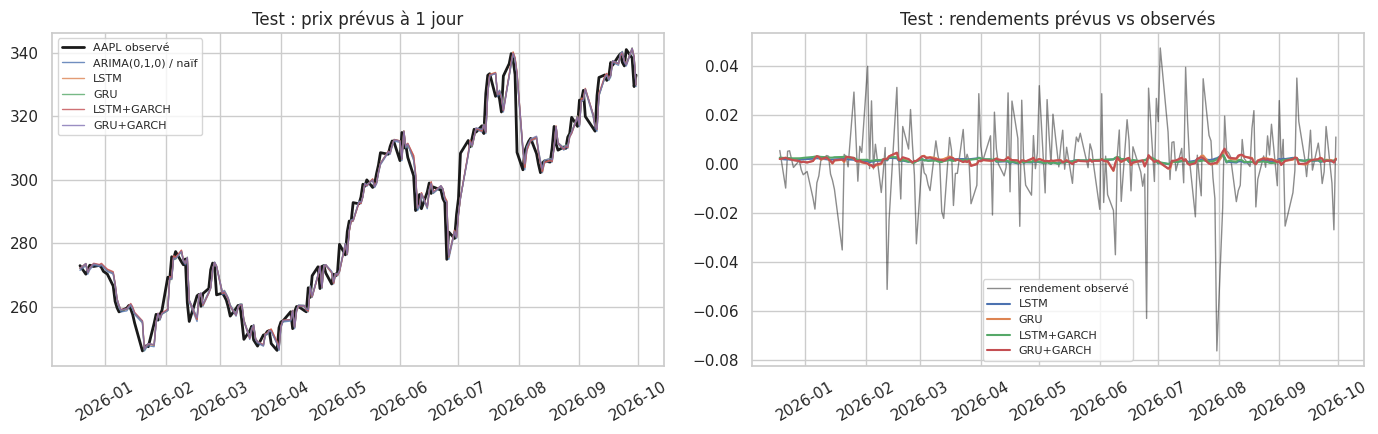

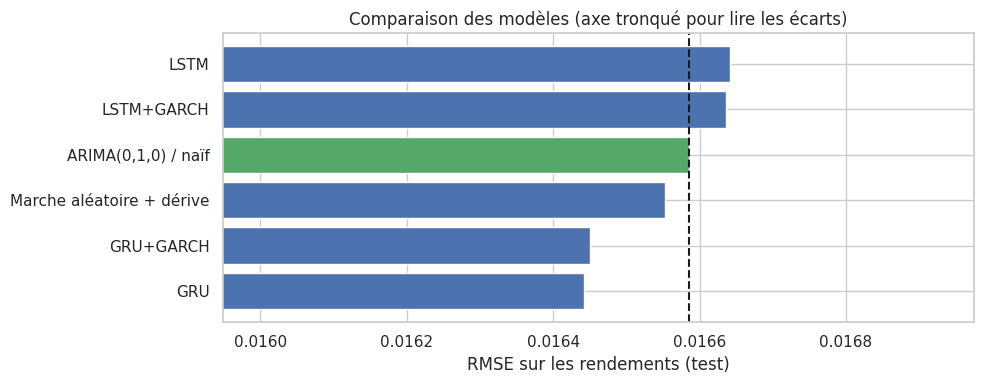

Lecture : sur les prix, toutes les courbes se superposent (le prix d'hier explique presque tout) ; c'est sur les RENDEMENTS que l'on voit si un modèle ajoute de l'information.


In [96]:
# --- Graphiques de test -------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(tgt_dates, P_next, "k", lw=2, label="AAPL observé")
for nm in ["ARIMA(0,1,0) / naïf", "LSTM", "GRU", "LSTM+GARCH", "GRU+GARCH"]:
    ax[0].plot(tgt_dates, P_org * np.exp(PRED[nm]), lw=1, alpha=.8, label=nm)
ax[0].set_title("Test : prix prévus à 1 jour"); ax[0].legend(fontsize=8); ax[0].tick_params(axis="x", rotation=30)
ax[1].plot(tgt_dates, r_next, "k", lw=1, alpha=.5, label="rendement observé")
for nm in ["LSTM", "GRU", "LSTM+GARCH", "GRU+GARCH"]:
    ax[1].plot(tgt_dates, PRED[nm], lw=1.5, label=nm)
ax[1].set_title("Test : rendements prévus vs observés"); ax[1].legend(fontsize=8); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 4))
order = results_df.sort_values("RMSE_ret").index
plt.barh(order, results_df.loc[order, "RMSE_ret"], color=["#55A868" if o == REF else "#4C72B0" for o in order])
plt.axvline(results_df.loc[REF, "RMSE_ret"], color="k", ls="--"); plt.xlabel("RMSE sur les rendements (test)")
lo_ = results_df["RMSE_ret"].min() * 0.97; plt.xlim(lo_, results_df["RMSE_ret"].max() * 1.02)
plt.title("Comparaison des modèles (axe tronqué pour lire les écarts)"); plt.tight_layout(); plt.show()
print("Lecture : sur les prix, toutes les courbes se superposent (le prix d'hier explique presque tout) ; c'est sur les RENDEMENTS que l'on voit si un modèle ajoute de l'information.")

In [97]:
# --- Sauvegarde pour la partie 6 (tableau récapitulatif unique) et pour la partie 5 ----------
results_df.to_csv(f"{OUT_DIR}/results_part4.csv")
pd.DataFrame({"P_t": P_org, "P_t+1": P_next, "r_t+1": r_next, **{f"rhat_{k}": v for k, v in PRED.items()}},
             index=tgt_dates).to_csv(f"{OUT_DIR}/predictions_test_part4.csv")
grid_df.to_csv(f"{OUT_DIR}/walkforward_grid_part4.csv", index=False)

best_name = results_df["RMSE_ret"].idxmin()
print(f"Meilleur RMSE (rendements, test) : {best_name} = {results_df.loc[best_name, 'RMSE_ret']:.5f} "
      f"| référence ARIMA(0,1,0) = {results_df.loc[REF, 'RMSE_ret']:.5f}")
print("Diebold-Mariano pour ce modèle :", results_df.loc[best_name, "verdict_vs_ARIMA"])
print("Fichiers écrits dans", OUT_DIR)

# --- État nécessaire à la partie 5 (prévisions J+1, dérive, paramètres GARCH figés) ---------
with open(f"{OUT_DIR}/state_part4.json", "w", encoding="utf-8") as f:
    json.dump({"NEXT": {k: float(v) for k, v in NEXT.items()},
               "drift": float(drift),
               "garch_params": {k: float(v) for k, v in garch_res.params.items()}}, f, ensure_ascii=False, indent=2)
print("state_part4.json écrit")

Meilleur RMSE (rendements, test) : GRU = 0.01644 | référence ARIMA(0,1,0) = 0.01659
Diebold-Mariano pour ce modèle : différence non significative
Fichiers écrits dans ../outputs


### Comment interpréter ces résultats (à rédiger dans le rapport avec VOS chiffres)

1. **Ordre de grandeur attendu** : sur des rendements quotidiens d'une action très liquide, le signal prévisible est minuscule (le R² d'un AR(1) à ρ ≈ −0.08 est ≈ 0.6 %). Un ratio RMSE/naïf très proche de 1 et un Diebold-Mariano **non significatif** ne sont donc **pas un échec** : c'est un résultat cohérent avec l'hypothèse d'efficience faible des marchés, et il est honnête de le rapporter (critère « honnêteté scientifique » du barème).
2. **Cohérence walk-forward ↔ test** : si le ratio moyen des plis est ≈ 1 et celui du test aussi, la conclusion est robuste. Une grande dispersion entre plis signale un résultat instable (régimes différents : 2020, 2022, avril 2025…).
3. **Dérive** : comparez toujours le réseau à la marche aléatoire *avec dérive*. Si le réseau n'est pas significativement meilleur qu'elle, son « avantage » sur le naïf n'est que le rendement moyen positif de la période d'apprentissage.
4. **Hit ratio** : un score proche de 50 % n'a aucune valeur d'investissement ; > 55 % de façon stable (et significatif) serait notable.
5. **Ablation GARCH** : l'ajout de σ̂ est utile s'il améliore la perte de façon significative ; sinon, la volatilité aide à *mesurer le risque* (GARCH) mais pas à *prévoir la direction* (réseau).
6. **Classique vs avancé** : à performance statistiquement égale, on préfère le modèle le plus **simple, interprétable et peu coûteux** (ARIMA/marche aléatoire) ; à citer dans le tableau de comparaison (interprétabilité, nombre de paramètres, temps de calcul).